# 05 - EEG during walking: brain signal or motion artefact?

**Question.** The dataset's distinctive feature is scalp EEG recorded during walking. Before any EEG
feature can be interpreted as cortical activity, it has to be shown that the signal is not dominated by
the mechanics of walking: electrode and cable movement, head acceleration at every step, and muscle
activity of the neck and face. This notebook tests that with four independent checks:

1. **Spectral peaks at the step frequency.** Brain rhythms have no reason to sit at exact multiples of a
   person's step frequency; mechanical artefacts do.
2. **Coherence with head acceleration**, compared against a null built from other participants' head
   acceleration at the same speed.
3. **Heel-strike-locked averages.** A transient that grows with walking speed and is largest at the
   electrodes most exposed to movement indicates mechanical origin.
4. **Do apparent "speed effects" on EEG band power survive adjustment for the artefact indices?**

Pre-processing: linked-ear re-reference (reconstructing Pz), 1 Hz high-pass, 50 Hz notch. No artefact
rejection is applied, deliberately: the aim is to characterise what the raw release contains.
Excluded: S32_1 (corrupted montage) and S8_0.5 (timing gap).

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import signal

from mgait import config as C, eeg as E, plotting as P, stats as S

P.use_style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
ec = pd.read_parquet(C.CACHE / "eeg_channels.parquet")
ec = ec[~((ec.subject == "S8") & (ec.speed == "0.5"))].reset_index(drop=True)
psd = np.load(C.CACHE / "eeg_psd.npz")
keys, f, Pw = list(psd["keys"]), psd["f"], psd["P"]
T = pd.read_parquet(C.TABLES / "trial_features.parquet")
fstep = ec.groupby(["subject", "speed"])["f_step"].first()
print(f"{ec.groupby(['subject', 'speed']).ngroups} EEG trials, {ec.subject.nunique()} participants; "
      f"step frequency {fstep.min():.2f} to {fstep.max():.2f} Hz")

175 EEG trials, 59 participants; step frequency 1.06 to 2.08 Hz


## 1. Spectral peaks locked to stepping

Each trial's spectrum is re-expressed against its own step frequency (frequency divided by step
frequency), so peaks caused by stepping line up at whole numbers across participants regardless of their
cadence. Spectra are averaged over channels within a region and over trials.

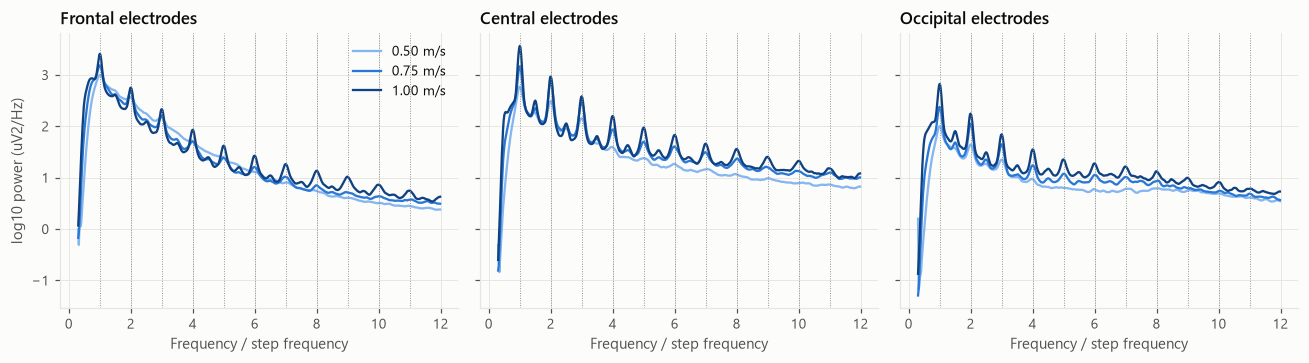

In [2]:
grid = np.arange(0.3, 12.0, 0.02)
reg_idx = {r: [C.EEG_CHANNELS.index(c) for c in chs] for r, chs in E.REGIONS.items()}
norm_spec = {s: {r: [] for r in E.REGIONS} for s in C.SPEEDS}
for i, k in enumerate(keys):
    s_, v_ = k.rsplit("_", 1)
    if (s_, v_) not in fstep.index or not np.isfinite(fstep[(s_, v_)]) or (s_ == "S8" and v_ == "0.5"):
        continue
    for r, idx in reg_idx.items():
        lp = np.log10(Pw[i][:, idx].mean(axis=1))
        norm_spec[v_][r].append(np.interp(grid, f / fstep[(s_, v_)], lp, left=np.nan, right=np.nan))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, r in zip(axes, ("frontal", "central", "occipital")):
    for s in C.SPEEDS:
        Mx = np.nanmean(norm_spec[s][r], axis=0)
        ax.plot(grid, Mx, color=P.SPEED_COLORS[s], lw=1.5, label=P.SPEED_LABEL[s])
    for h in range(1, 12):
        ax.axvline(h, color=P.MUTED, lw=0.6, ls=":")
    ax.set_title(f"{r.capitalize()} electrodes")
    ax.set_xlabel("Frequency / step frequency")
axes[0].set_ylabel("log10 power (uV2/Hz)")
axes[0].legend()
fig.tight_layout()
P.save(fig, "05_step_locked_spectra")
plt.show()

In [3]:
ec["log_hr"] = np.log10(ec["harmonic_ratio"])
hr_ch = ec.groupby(["channel", "speed"])["harmonic_ratio"].median().unstack("speed")[C.SPEEDS].reindex(C.EEG_CHANNELS)
display(hr_ch.round(2).T)
share = (ec["harmonic_ratio"] > 1.5).groupby(ec["speed"]).mean() * 100
print("Channel-trials with gait-harmonic power at least 1.5x the neighbouring bands (%):", share.round(0).to_dict())
tr_any = ec.assign(peak=ec["harmonic_ratio"] > 1.5).groupby(["subject", "speed"])["peak"].sum()
print(f"Trials with a step-locked peak on at least 5 of 19 channels: {(tr_any >= 5).mean() * 100:.0f} %")
d = ec.groupby(["subject", "speed"])["log_hr"].mean().reset_index().merge(T[["subject", "speed", "speed_ms"]])
r = S.mixed_model(d.rename(columns={"log_hr": "y"}), "y ~ speed_ms")
print(f"Mean log10 harmonic ratio rises by {0.5 * r.params['speed_ms']:.3f} per +0.5 m/s "
      f"(x{10 ** (0.5 * r.params['speed_ms']):.2f}), p = {r.pvalues['speed_ms']:.1e}")

channel,Fp1,Fp2,F7,F3,Fz,F4,F8,T3,C3,Cz,C4,T4,T5,P3,Pz,P4,T6,O1,O2
speed,,,,,,,,,,,,,,,,,,,
0.5,1.42,1.39,1.54,1.59,1.55,2.00,1.44,1.43,2.11,2.76,2.36,1.49,1.49,2.02,2.37,1.81,1.45,1.87,1.70
0.75,1.14,1.17,1.61,2.30,2.03,3.46,1.38,1.79,3.57,4.51,3.91,1.89,2.32,3.11,4.52,3.28,2.62,4.11,2.66
1,1.13,1.20,1.61,3.73,3.10,7.78,1.44,1.98,5.82,6.00,8.80,2.76,3.67,4.70,6.71,6.16,3.10,5.87,3.47


Channel-trials with gait-harmonic power at least 1.5x the neighbouring bands (%): {'0.5': 60.0, '0.75': 70.0, '1': 76.0}
Trials with a step-locked peak on at least 5 of 19 channels: 94 %
Mean log10 harmonic ratio rises by 0.313 per +0.5 m/s (x2.05), p = 4.3e-52


Peaks sit exactly at multiples of each person's step frequency at all three speeds and in every region,
and they grow with speed. This pattern is the signature of a mechanical source driven by stepping.

## 2. Coherence with head acceleration

Coherence between each EEG channel and vertical head acceleration (from the IMU head segment) is compared
with the coherence obtained when the head acceleration is taken from *other* participants walking at the
same speed. Those surrogates share the same broad rhythm but not the step-by-step timing, so they give the
coherence expected by chance for a periodic signal. (A time-shifted copy of the same recording would not be
a valid null, because coherence is insensitive to a constant shift.)

Trials: 168. Mean coherence with own head acceleration 0.151 vs surrogate 0.037; own exceeds surrogate in 98 % of trials
Wilcoxon signed-rank on per-trial excess: p = 3.0e-29


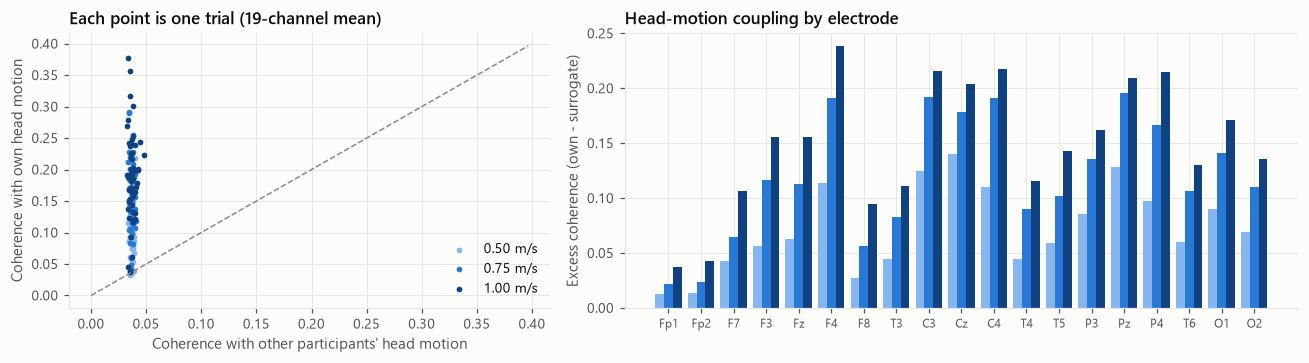

In [4]:
z = np.load(C.CACHE / "eeg_head60.npz")
eeg_keys = sorted(k[4:] for k in z.files if k.startswith("eeg_"))
head_keys = {k[5:] for k in z.files if k.startswith("head_")}
both = [k for k in eeg_keys if k in head_keys and k != "S8_0.5"]

def coh_one(k, n_sur=8, seed=0):
    z = np.load(C.CACHE / "eeg_head60.npz")   # opened per worker (file handles cannot be shared)
    x, h = z[f"eeg_{k}"], z[f"head_{k}"]
    spd = k.rsplit("_", 1)[1]
    pool = [o for o in both if o.rsplit("_", 1)[1] == spd and o.split("_")[0] != k.split("_")[0]]
    rng = np.random.default_rng(abs(hash(k)) % 2**32)
    def mean_coh(hh):
        n = min(len(x), len(hh))
        out = []
        for j in range(x.shape[1]):
            ff, c = signal.coherence(x[:n, j], hh[:n], fs=C.FS_IMU, nperseg=int(4 * C.FS_IMU))
            out.append(c[(ff >= 0.5) & (ff <= 10)].mean())
        return np.array(out)
    own = mean_coh(h)
    sur = np.mean([mean_coh(z[f"head_{o}"]) for o in rng.choice(pool, size=n_sur, replace=False)], axis=0)
    return k, own, sur

res = Parallel(n_jobs=-1)(delayed(coh_one)(k) for k in both)
coh = pd.DataFrame([{"trial": k, "subject": k.split("_")[0], "speed": k.rsplit("_", 1)[1], "channel": ch,
                     "own": o[j], "surrogate": s_[j]} for k, o, s_ in res for j, ch in enumerate(C.EEG_CHANNELS)])
coh["excess"] = coh["own"] - coh["surrogate"]
ct = coh.groupby("trial")[["own", "surrogate", "excess"]].mean()
print(f"Trials: {len(ct)}. Mean coherence with own head acceleration {ct['own'].mean():.3f} vs surrogate {ct['surrogate'].mean():.3f}; "
      f"own exceeds surrogate in {(ct['excess'] > 0).mean() * 100:.0f} % of trials")
from scipy import stats as st
w = st.wilcoxon(ct["excess"])
print(f"Wilcoxon signed-rank on per-trial excess: p = {w.pvalue:.1e}")
coh.to_csv(C.TABLES / "eeg_head_coherence.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1, 1.4]})
for s in C.SPEEDS:
    cs_ = coh[coh.speed == s].groupby("trial")[["own", "surrogate"]].mean()
    axes[0].scatter(cs_["surrogate"], cs_["own"], s=14, color=P.SPEED_COLORS[s], label=P.SPEED_LABEL[s])
lim = [0, max(ct["own"].max(), ct["surrogate"].max()) * 1.05]
axes[0].plot(lim, lim, color=P.MUTED, ls="--", lw=1)
axes[0].set_xlabel("Coherence with other participants' head motion")
axes[0].set_ylabel("Coherence with own head motion")
axes[0].set_title("Each point is one trial (19-channel mean)")
axes[0].legend()
ex = coh.groupby(["channel", "speed"])["excess"].mean().unstack("speed").reindex(C.EEG_CHANNELS)[C.SPEEDS]
xx = np.arange(len(C.EEG_CHANNELS))
for i, s in enumerate(C.SPEEDS):
    axes[1].bar(xx + (i - 1) * 0.27, ex[s], width=0.27, color=P.SPEED_COLORS[s], label=P.SPEED_LABEL[s])
axes[1].set_xticks(xx, C.EEG_CHANNELS, fontsize=8)
axes[1].set_ylabel("Excess coherence (own - surrogate)")
axes[1].set_title("Head-motion coupling by electrode")
fig.tight_layout()
P.save(fig, "05_head_coherence")
plt.show()

## 3. Heel-strike-locked averages

EEG averaged around every heel strike (IMU events, 1-30 Hz). A cortical event-related potential would be a
few microvolts and similar across speeds; a mechanical transient scales with impact and head acceleration.

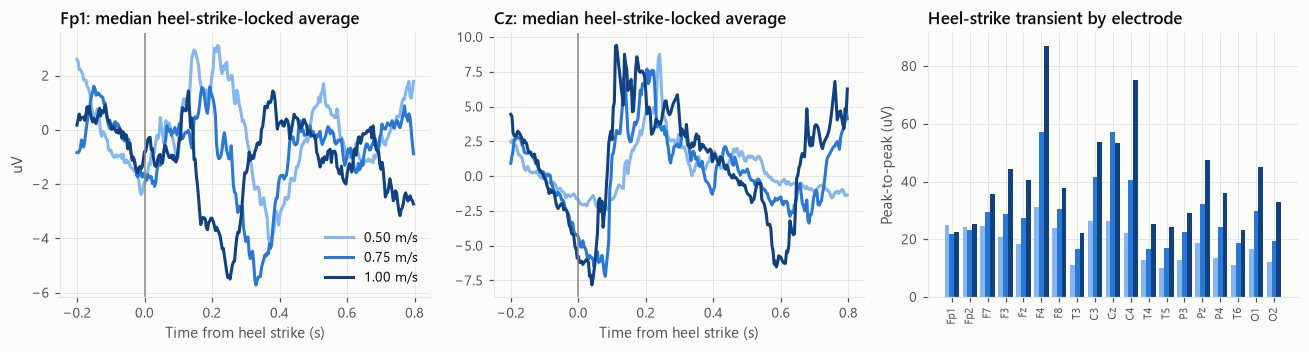

Heel-strike-locked peak-to-peak amplitude (median over channels): {'0.5': 19.700000762939453, '0.75': 26.299999237060547, '1': 33.900001525878906} uV; x1.90 per +0.5 m/s, p = 2.9e-35


In [5]:
erp = np.load(C.CACHE / "eeg_erp.npz")
ek, E_ = list(erp["keys"]), erp["erp"]
tt = np.arange(E_.shape[1]) / C.FS_EEG - 0.2
amp = []
for i, k in enumerate(ek):
    s_, v_ = k.rsplit("_", 1)
    if k == "S8_0.5":
        continue
    for j, ch in enumerate(C.EEG_CHANNELS):
        amp.append({"subject": s_, "speed": v_, "channel": ch, "p2p": np.ptp(E_[i, :, j])})
amp = pd.DataFrame(amp)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, ch in zip(axes[:2], ("Fp1", "Cz")):
    j = C.EEG_CHANNELS.index(ch)
    for s in C.SPEEDS:
        sel = [i for i, k in enumerate(ek) if k.rsplit("_", 1)[1] == s and k != "S8_0.5"]
        Mx = np.nanmedian(E_[sel, :, j], axis=0)
        ax.plot(tt, Mx, color=P.SPEED_COLORS[s], label=P.SPEED_LABEL[s])
    ax.axvline(0, color=P.MUTED, lw=1)
    ax.set_title(f"{ch}: median heel-strike-locked average")
    ax.set_xlabel("Time from heel strike (s)")
axes[0].set_ylabel("uV"); axes[0].legend()
pp = amp.groupby(["channel", "speed"])["p2p"].median().unstack("speed").reindex(C.EEG_CHANNELS)[C.SPEEDS]
for i, s in enumerate(C.SPEEDS):
    axes[2].bar(xx + (i - 1) * 0.27, pp[s], width=0.27, color=P.SPEED_COLORS[s])
axes[2].set_xticks(xx, C.EEG_CHANNELS, fontsize=7, rotation=90)
axes[2].set_ylabel("Peak-to-peak (uV)")
axes[2].set_title("Heel-strike transient by electrode")
fig.tight_layout()
P.save(fig, "05_heelstrike_locked")
plt.show()
dd = amp.groupby(["subject", "speed"])["p2p"].median().reset_index().merge(T[["subject", "speed", "speed_ms"]])
dd["y"] = np.log10(dd["p2p"])
r = S.mixed_model(dd, "y ~ speed_ms")
print(f"Heel-strike-locked peak-to-peak amplitude (median over channels): {dd.groupby('speed')['p2p'].median().round(1).to_dict()} uV; "
      f"x{10 ** (0.5 * r.params['speed_ms']):.2f} per +0.5 m/s, p = {r.pvalues['speed_ms']:.1e}")

## 4. Topography of the contamination

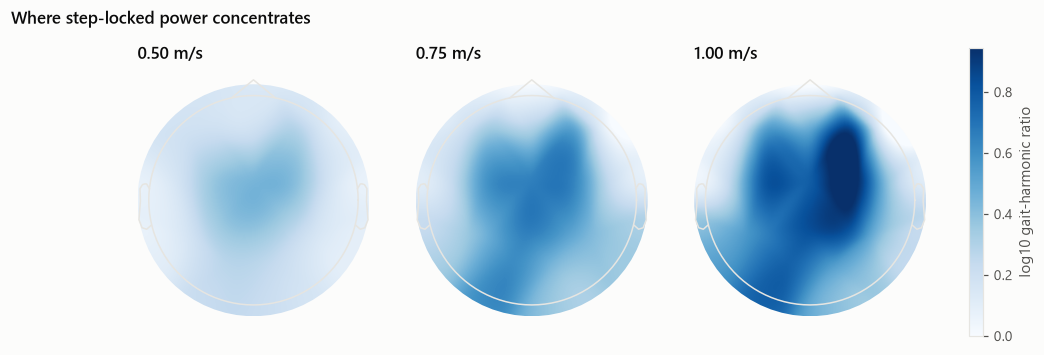

In [6]:
import mne
mne.set_log_level("ERROR")
info = mne.create_info(C.EEG_CHANNELS, 300.0, "eeg")
info.set_montage(mne.channels.make_standard_montage("standard_1020"))
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, s in zip(axes, C.SPEEDS):
    vals = np.log10(hr_ch[s].to_numpy())
    im, _ = mne.viz.plot_topomap(vals, info, axes=ax, show=False, cmap="Blues", vlim=(0, np.log10(hr_ch.max().max())),
                                 contours=0, sensors=True)
    ax.set_title(P.SPEED_LABEL[s])
cb = fig.colorbar(im, ax=axes, fraction=0.025)
cb.set_label("log10 gait-harmonic ratio")
fig.suptitle("Where step-locked power concentrates", x=0.01, ha="left", fontsize=11, fontweight="semibold")
P.save(fig, "05_topography")
plt.show()

## 5. Do apparent EEG speed effects survive artefact adjustment?

Relative band power is modelled against speed with and without the two artefact indices (mean gait-harmonic
ratio and head-motion coherence of the trial) as covariates. If a band's speed effect is cortical, it should
persist after adjustment; if it reflects artefact, it should shrink.

In [7]:
rows = []
for region in ("frontal", "central", "parietal", "occipital"):
    for band in E.BANDS:
        col = f"eeg_{region}_rel_{band}"
        d = T[["subject", "speed_ms", col, f"eeg_{region}_harmonic_ratio", f"eeg_{region}_head_coherence"]].dropna()
        d.columns = ["subject", "speed_ms", "y", "hr", "coh"]
        r0 = S.mixed_model(d, "y ~ speed_ms")
        r1 = S.mixed_model(d, "y ~ speed_ms + hr + coh")
        rows.append({"region": region, "band": band, "speed effect (SD/0.5 m/s)": 0.5 * r0.params["speed_ms"] / d["y"].std(),
                     "p": r0.pvalues["speed_ms"],
                     "adjusted effect": 0.5 * r1.params["speed_ms"] / d["y"].std(), "p adjusted": r1.pvalues["speed_ms"],
                     "artefact index p (hr)": r1.pvalues["hr"]})
adj = pd.DataFrame(rows)
adj["p_holm"] = S.holm(adj["p"].to_numpy())
adj["p_adj_holm"] = S.holm(adj["p adjusted"].to_numpy())
adj.to_csv(C.TABLES / "eeg_speed_effects_adjusted.csv", index=False)
display(adj.set_index(["region", "band"]).round(3))
n_sig = int((adj["p_holm"] < 0.05).sum()); n_sig_adj = int((adj["p_adj_holm"] < 0.05).sum())
print(f"Band-region speed effects significant after Holm: {n_sig} of {len(adj)} unadjusted, {n_sig_adj} after artefact adjustment")

speed effect (SD/0.5 m/s)      p  adjusted effect  p adjusted  artefact index p (hr)  p_holm  p_adj_holm
region    band                                                                                                           
frontal   delta                     -0.187  0.075            0.210       0.164                  0.281   0.522       1.000
          theta                     -0.027  0.792           -0.167       0.272                  0.011   1.000       1.000
          alpha                      0.542  0.000            0.214       0.116                  0.137   0.000       1.000
          beta                       0.382  0.001           -0.151       0.331                  0.345   0.006       1.000
          gamma                     -0.243  0.056           -0.430       0.018                  0.235   0.445       0.312
central   delta                      0.325  0.004            0.175       0.273                  0.026   0.042       1.000
          theta                     -0.212  0.079           -0.239       0.145                  0.104   0.522       1.000
          alpha                     -0.090  0.419            0.102       0.508                  0.008   1.000       1.000
          beta                      -0.192  0.099           -0.056       0.739                  0.328   0.522       1.000
          gamma                     -0.328  0.010           -0.103       0.575                  0.211   0.094       1.000
parietal  delta                      0.533  0.000            0.490       0.002                  0.285   0.000       0.038
          theta                     -0.193  0.139           -0.222       0.274                  0.593   0.556       1.000
          alpha                     -0.252  0.000           -0.154       0.161                  0.274   0.001       1.000
          beta                      -0.381  0.000           -0.415       0.009                  0.753   0.000       0.156
          gamma                     -0.656  0.000           -0.652       0.000                  0.396   0.000       0.003
occipital delta                      0.519  0.000            0.181       0.173                  0.003   0.000       1.000
          theta                     -0.077  0.471           -0.182       0.235                  0.681   1.000       1.000
          alpha                     -0.417  0.000           -0.162       0.146                  0.005   0.000       1.000
          beta                      -0.396  0.000           -0.085       0.472                  0.014   0.000       1.000
          gamma                     -0.464  0.000           -0.163       0.246                  0.027   0.000       1.000

Band-region speed effects significant after Holm: 11 of 20 unadjusted, 2 after artefact adjustment


## 6. Summary

All four checks point the same way:

| Check | Result |
|---|---|
| Step-locked spectral peaks | Present on at least 5 of 19 channels in 94 % of trials; their strength doubles per +0.5 m/s (p < 1e-50) |
| Coupling to head motion | Coherence with own head acceleration 0.15 vs 0.04 for other participants' motion; higher in 97 % of trials |
| Heel-strike transient | 20, 26 and 34 uV peak-to-peak at 0.5, 0.75 and 1.0 m/s (x1.9 per +0.5 m/s), several times a typical cortical evoked response |
| Speed effects on band power | 11 of 20 region-band effects significant; 2 remain after adjusting for the artefact indices |

The contamination is not uniform. It is strongest at the vertex and centro-parietal electrodes (Cz, C4,
Pz, F4), which carry the most headset and cable movement; the frontal pole electrodes (Fp1, Fp2) have the
highest raw amplitude but little step-locked structure, consistent with eye and facial muscle activity
rather than stepping.

**Implication.** In this release, walking-related changes in EEG band power cannot be attributed to the
brain without artefact removal designed for mobile EEG (for example artefact subspace reconstruction and
independent component analysis with head-motion reference channels). Any model that "decodes" walking
speed from these EEG features should be presumed to read the mechanics of walking; notebook 06 tests this
directly. The two effects that survive adjustment (parietal delta and gamma) are candidates for follow-up,
not findings.